# Analiza jakości powietrza
Krzysztof Kata 254776
Zadanie 3

Celem zadania jest analiza stężenia tlenku węgla CO i wykonanie prostej prognozy na kolejne 7 dni.

Źródło: Air Quality, UCI Machine Learning Repository
https://archive.ics.uci.edu/dataset/360/air+quality

Wykorzystano kolumnę CO(GT), podającą stężenie CO w mg/m3.

Liczba pomiarów: 9357
Braki CO: 1683


,CO(GT)
2004-03-10 18:00:00,2.6
2004-03-10 19:00:00,2.0
2004-03-10 20:00:00,2.2
2004-03-10 21:00:00,2.2
2004-03-10 22:00:00,1.6


,CO [mg/m3]
mean,2.15275
min,0.10000
max,11.90000


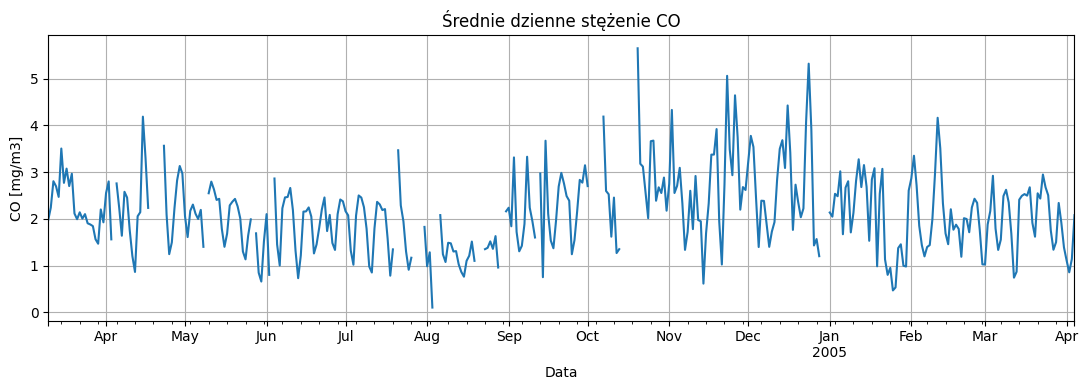

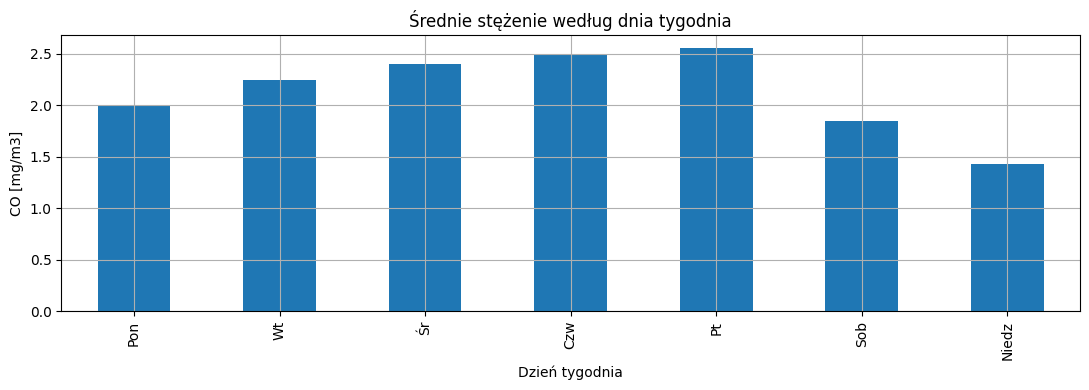

Trend: +0.0005 mg/m3 na dobę


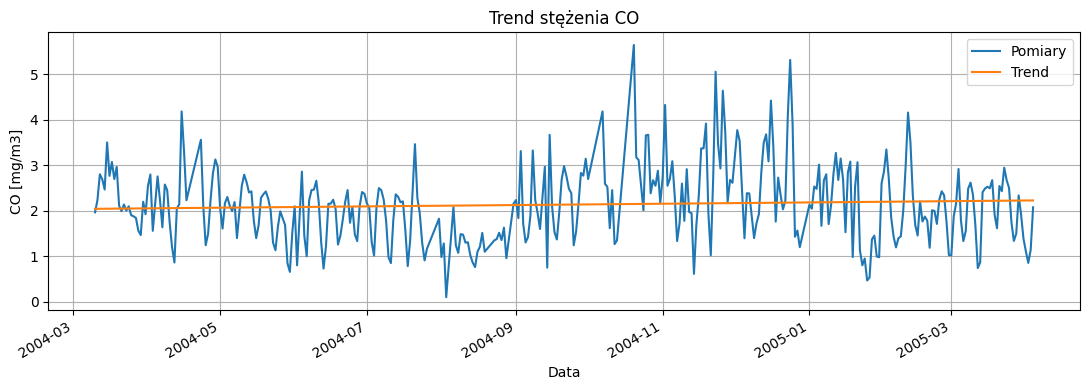

In [24]:
import io
import zipfile
import requests
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

url = "https://archive.ics.uci.edu/static/public/360/air+quality.zip"
plik = requests.get(url, timeout=60)
plik.raise_for_status()

with zipfile.ZipFile(io.BytesIO(plik.content)) as archiwum:dane = pd.read_csv(archiwum.open("AirQualityUCI.csv"),sep=";", decimal=",", na_values=-200)

dane = dane.dropna(subset=["Date", "Time"])
dane.index = pd.to_datetime(
dane["Date"] + " " + dane["Time"], format="%d/%m/%Y %H.%M.%S")
dane = dane.sort_index()
co = dane["CO(GT)"].resample("D").mean()

print("Liczba pomiarów:", len(dane))
print("Braki CO:", dane["CO(GT)"].isna().sum())
display(dane[["CO(GT)"]].head())
display(dane["CO(GT)"].agg(["mean", "min", "max"]).rename("CO [mg/m3]"))


def wykres(tabela, tytul, rodzaj="line"):
    tabela.plot(kind=rodzaj, figsize=(11, 4), grid=True)
    plt.title(tytul)
    plt.ylabel("CO [mg/m3]")
    plt.xlabel("Dzień tygodnia" if rodzaj == "bar" else "Data")
    plt.tight_layout()
    plt.show()


wykres(co, "Średnie dzienne stężenie CO")

tydzien = co.groupby(co.index.dayofweek).mean()
tydzien.index = ["Pon", "Wt", "Śr", "Czw", "Pt", "Sob", "Niedz"]
wykres(tydzien, "Średnie stężenie według dnia tygodnia", "bar")

trend = co.dropna().to_frame("Pomiary")
dni = (trend.index - trend.index[0]).days.to_numpy().reshape(-1, 1)
model_trendu = LinearRegression().fit(dni, trend["Pomiary"])
trend["Trend"] = model_trendu.predict(dni)

print(f"Trend: {model_trendu.coef_[0]:+.4f} mg/m3 na dobę")
wykres(trend, "Trend stężenia CO")

## Budowa i sprawdzenie modelu

Do prognozowania wykorzystano regresję liniową z biblioteki scikit-learn. Model korzysta ze stężenia CO z poprzedniego dnia, sprzed tygodnia oraz informacji o dniu tygodnia. Ostatnie 7 dni przeznaczono do testowania, a wcześniejsze dane do uczenia.

Prognoza powstaje kolejno dla każdego dnia. W kolejnych krokach model
wykorzystuje własne wcześniejsze przewidywania zamiast przyszłych pomiarów Jakość oceniono za pomocą MAE, czyli średniego błędu bezwzględnego
w mg/m³. Im mniejszy wynik, tym lepsza prognoza.
Dla porównania sprawdzono również prognozę zakładającą utrzymanie
ostatniego znanego stężenia przez cały tydzień.

Liczba przykładów uczących: 297
MAE modelu: 0.63
MAE prostej prognozy: 0.48
Jednostka MAE: mg/m³


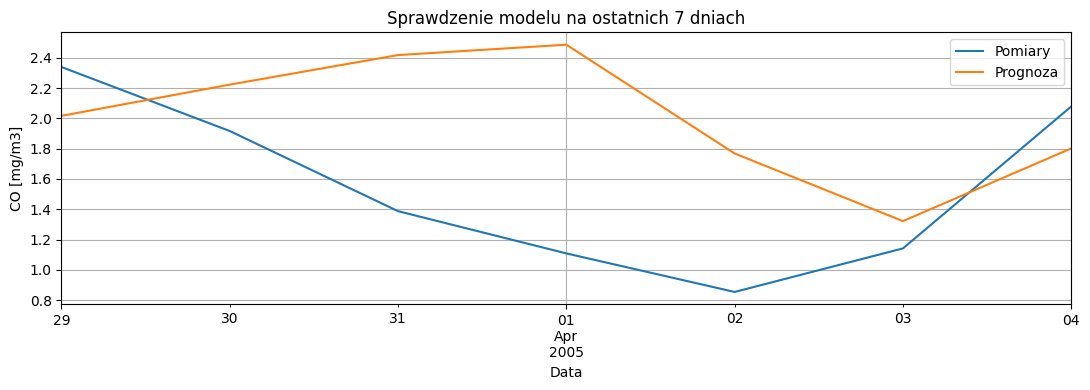

In [ ]:
tabela = pd.DataFrame({
    "CO": co,
    "wczoraj": co.shift(1),
    "tydzien_temu": co.shift(7)
})

for dzien in range(6):
    tabela[f"dzien_{dzien}"] = (tabela.index.dayofweek == dzien).astype(int)

cechy = tabela.columns.drop("CO")
test = co.iloc[-7:]
trening = tabela.loc[tabela.index < test.index[0]].dropna()
model = LinearRegression().fit(trening[cechy], trening["CO"])


def prognozuj(historia, daty):
    historia = historia.copy()
    for data in daty:
        wejscie = pd.DataFrame([[
            historia.loc[data - pd.Timedelta(days=1)],
            historia.loc[data - pd.Timedelta(days=7)],
            *[int(data.dayofweek == dzien) for dzien in range(6)]
        ]], columns=cechy)

        if wejscie.isna().any().any():
            raise ValueError("Brakuje wcześniejszych pomiarów do prognozy")

        historia.loc[data] = model.predict(wejscie)[0]

    return historia.loc[daty]


historia = co.loc[co.index < test.index[0]]
wyniki = prognozuj(historia, test.index)
ocena = pd.DataFrame({"Pomiary": test, "Prognoza": wyniki}).dropna()

print("Liczba przykładów uczących:", len(trening))
print(f"MAE modelu: {mean_absolute_error(ocena['Pomiary'], ocena['Prognoza']):.2f}")
print(f"MAE prostej prognozy: {mean_absolute_error(ocena['Pomiary'], [historia.dropna().iloc[-1]] * len(ocena)):.2f}")
print("Jednostka MAE: mg/m3")

wykres(
    pd.DataFrame({"Pomiary": test, "Prognoza": wyniki}),
    "Sprawdzenie modelu na ostatnich 7 dniach"
)

## Prognoza na kolejne 7 dni

Po sprawdzeniu jakości model ponownie nauczono na wszystkich dostępnych przykładach. Następnie przewidziano średnie dzienne stężenie CO na 7 dni po zakończeniu zbioru.

,Prognoza CO [mg/m3]
2005-04-05,2.33
2005-04-06,2.27
2005-04-07,2.29
2005-04-08,2.26
2005-04-09,1.55
2005-04-10,1.19
2005-04-11,1.80


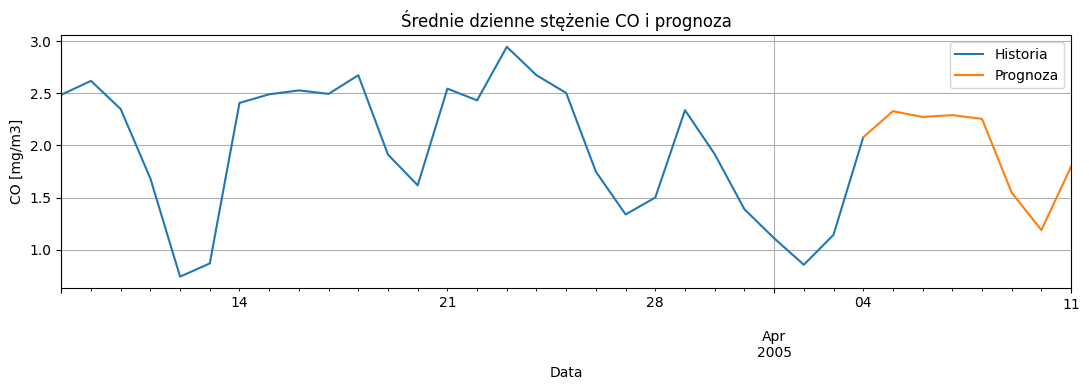

In [26]:
pelne = tabela.dropna()
model.fit(pelne[cechy], pelne["CO"])

daty = pd.date_range(co.index[-1] + pd.Timedelta(days=1), periods=7)
prognoza = prognozuj(co, daty)

display(prognoza.rename("Prognoza CO [mg/m3]").round(2).to_frame())

wykres(pd.DataFrame({
    "Historia": co.tail(28),
    "Prognoza": pd.concat([co.iloc[-1:], prognoza])
}), "Średnie dzienne stężenie CO i prognoza")

## Wnioski

Średnie stężenie CO wyniosło 2,15275 mg/m³.
Najmniejsza wartość wyniosła 0,1 mg/m³, a największa 11,9 mg/m³.

Na wykresach widać, że stężenie CO zmieniało się w czasie.Trend dla całego okresu wskazuje na wzrost stężenia. MAE modelu wyniosło 0.63 mg/m³, a prostej prognozy 0.48 mg/m³. Model uzyskał więc gorszy wynik niż prosta prognoza.

Prognoza na kolejny tydzień wskazuje na utrzymanie stężenia w tygodniu i spadek w weekend.